# PHẦN III VÀ IV: TRỰC QUAN HOÁ DỮ LIỆU ĐA CHIỀU, TỔNG HỢP VÀ BÁO CÁO

In [13]:
# Import numpy và pandas để xử lý dữ liệu
import os
import numpy as np
import pandas as pd
# Import matplotlib và seaborn để vẽ biểu đồ
import matplotlib.pyplot as plt
import seaborn as sns
# Import Markdown, display để in nhận xét có định dạng ngay dưới kết quả (giống Phần I)
from IPython.display import Markdown, display

# ---------- settings (giống Phần I và Phần II) ----------
# Đọc file do Phần II lưu: ưu tiên thư mục shared, nếu không có thì dùng thư mục hiện tại
DUONG_DAN = "../shared/students_part2.csv" if os.path.exists("../shared/students_part2.csv") else "students_part2.csv"
# Thư mục lưu biểu đồ (Phần I đã đặt tên charts cho Phần III)
CHART_FOLDER = "charts"
os.makedirs(CHART_FOLDER, exist_ok=True)

DIEM = ["math_score", "reading_score", "writing_score"]     # 3 cột điểm gốc
TB = "diem_trung_binh"                                      # cột điểm trung bình (tạo ở Phần II)
GROUP_COL = "race_ethnicity"                                # cột nhóm chính (giống Phần II)
# Thứ tự hiển thị của các cột phân loại có thứ bậc
THU_TU_XEP_LOAI = ["Yếu", "Trung bình", "Khá", "Giỏi"]
THU_TU_HOC_VAN = ["some high school", "high school", "some college",
                  "associate's degree", "bachelor's degree", "master's degree"]
THU_TU = {"xep_loai": THU_TU_XEP_LOAI, "parental_level_of_education": THU_TU_HOC_VAN}
# Các yếu tố (biến độc lập) dùng để giải thích điểm; không dùng xep_loai và ket_qua vì chúng được tính từ chính điểm số
CAC_YEU_TO = ["gender", "race_ethnicity", "parental_level_of_education", "lunch", "test_preparation_course"]

# Đọc dữ liệu
df = pd.read_csv(DUONG_DAN)
print("Đã đọc:", DUONG_DAN, "| kích thước:", df.shape)

# xep_loai là cột có thứ bậc: đặt kiểu Categorical để biểu đồ và bảng luôn theo đúng thứ tự Yếu < Trung bình < Khá < Giỏi
df["xep_loai"] = pd.Categorical(df["xep_loai"], categories=THU_TU_XEP_LOAI, ordered=True)

# Kiểm tra các cột cần dùng đã có đủ chưa
cot_can = DIEM + [TB, "xep_loai", "ket_qua"] + CAC_YEU_TO
cot_thieu = [c for c in cot_can if c not in df.columns]
print("Các cột còn thiếu:", cot_thieu if cot_thieu else "không có")

# Kiểu hiển thị chung cho mọi biểu đồ
sns.set_theme(style="whitegrid")

def luu_hinh(ten_file):
    """Lưu biểu đồ hiện tại vào thư mục charts rồi hiển thị."""
    plt.tight_layout()
    plt.savefig(os.path.join(CHART_FOLDER, ten_file + ".png"), dpi=150, bbox_inches="tight")
    plt.show()

Đã đọc: ../shared/students_part2.csv | kích thước: (1000, 18)
Các cột còn thiếu: không có


# PHẦN III: TRỰC QUAN HOÁ DỮ LIỆU ĐA CHIỀU

Sử dụng kết quả của Phần II (các cột `diem_trung_binh`, `xep_loai`, `ket_qua`) để trực quan hoá phân bố, so sánh nhóm và mối quan hệ giữa các biến.

## 3.1 Phân bố (Distribution)

#### Histogram hiển thị sự phân bố, Box Plot so sánh sự phân bố.

### 3.1.1 Histogram

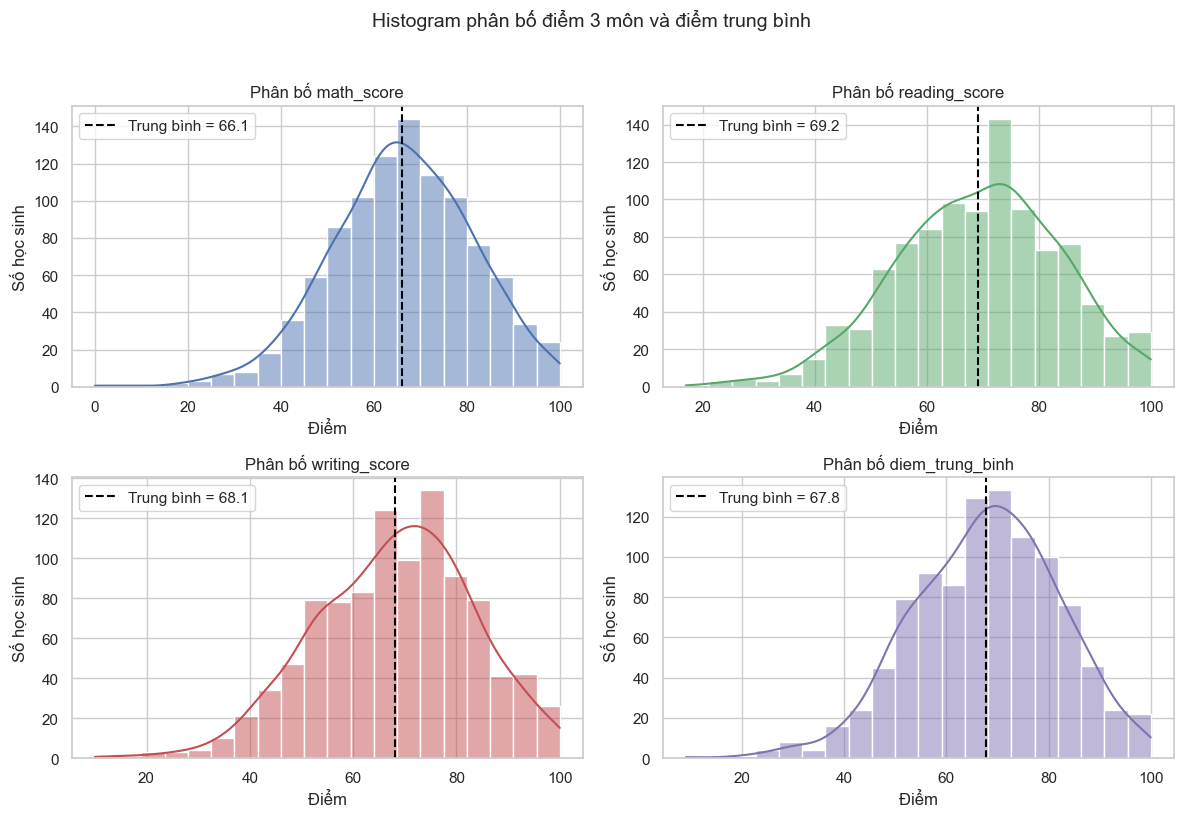

        math_score  reading_score  writing_score  diem_trung_binh
mean         66.09          69.17          68.05            67.77
median       66.00          70.00          69.00            68.33
std          15.16          14.60          15.20            14.26
skew         -0.28          -0.26          -0.29            -0.30
min           0.00          17.00          10.00             9.00
max         100.00         100.00         100.00           100.00


**Nhận xét:** Điểm trung bình của math, reading, writing lần lượt là 66.09, 69.17, 68.05; điểm trung bình chung là 67.77 (trung vị 68.33, độ lệch chuẩn 14.26). Các cột math_score, reading_score, writing_score, diem_trung_binh có độ lệch âm (đuôi bên trái dài), nghĩa là có một số ít học sinh điểm rất thấp kéo đuôi về bên trái. Điểm thấp nhất của math là 0.0 và của writing là 10.0, trong khi điểm cao nhất của cả ba môn đều gần 100.0.

In [14]:
# 4 cột cần xem phân bố: 3 điểm gốc và điểm trung bình (cột mới của Phần II)
cac_cot = DIEM + [TB]
mau = ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]

# Tạo lưới 2 x 2 biểu đồ; axes.flat duyệt từng ô theo thứ tự
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, cot, m in zip(axes.flat, cac_cot, mau):
    # histplot vẽ histogram; bins là số cột; kde=True vẽ thêm đường mật độ
    sns.histplot(data=df, x=cot, bins=20, kde=True, color=m, ax=ax)
    # Đường nét đứt đánh dấu điểm trung bình
    ax.axvline(df[cot].mean(), color="black", linestyle="--", label=f"Trung bình = {df[cot].mean():.1f}")
    ax.set_title("Phân bố " + cot)
    ax.set_xlabel("Điểm")
    ax.set_ylabel("Số học sinh")
    ax.legend()
fig.suptitle("Histogram phân bố điểm 3 môn và điểm trung bình", fontsize=14, y=1.02)
luu_hinh("3_1_1_histogram")

# Thống kê đi kèm để viết nhận xét
thong_ke = df[cac_cot].agg(["mean", "median", "std", "skew", "min", "max"]).round(2)
print(thong_ke)

# Cột có độ lệch (skew) âm rõ rệt (< -0,1): đuôi bên trái dài, tức có một số học sinh điểm rất thấp
lech_am = [c for c in cac_cot if df[c].skew() < -0.1]
cau_lech = (f"Các cột {', '.join(lech_am)} có độ lệch âm (đuôi bên trái dài), nghĩa là có một số ít học sinh điểm rất thấp kéo đuôi về bên trái. "
            if lech_am else "Các phân bố gần đối xứng, không lệch rõ về phía nào. ")
display(Markdown(
    f"**Nhận xét:** Điểm trung bình của math, reading, writing lần lượt là "
    f"{thong_ke.loc['mean', 'math_score']}, {thong_ke.loc['mean', 'reading_score']}, {thong_ke.loc['mean', 'writing_score']}; "
    f"điểm trung bình chung là {thong_ke.loc['mean', TB]} (trung vị {thong_ke.loc['median', TB]}, độ lệch chuẩn {thong_ke.loc['std', TB]}). "
    + cau_lech +
    f"Điểm thấp nhất của math là {thong_ke.loc['min', 'math_score']} và của writing là {thong_ke.loc['min', 'writing_score']}, "
    f"trong khi điểm cao nhất của cả ba môn đều gần {thong_ke.loc['max', DIEM].max()}."
))

### 3.1.2 Box Plot (so sánh phân bố)

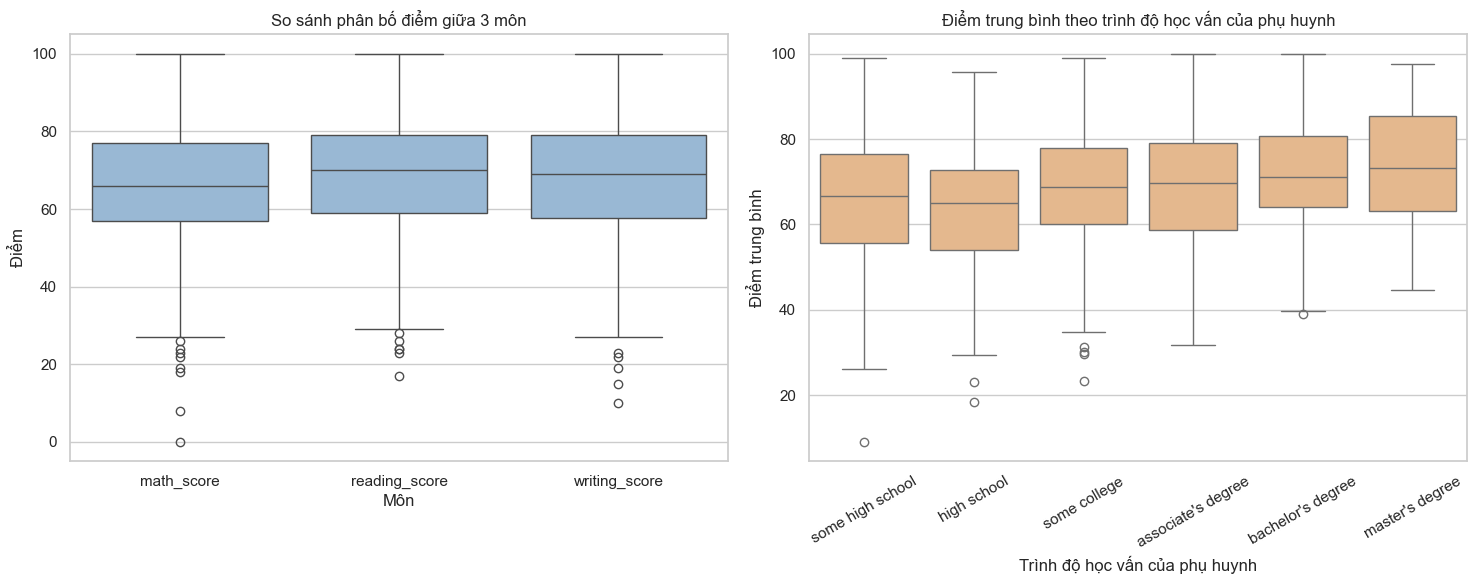

Số ngoại lai: {'math_score': 8, 'reading_score': 6, 'writing_score': 5}
parental_level_of_education
some high school      66.67
high school           65.00
some college          68.67
associate's degree    69.67
bachelor's degree     71.16
master's degree       73.33
Name: diem_trung_binh, dtype: float64


**Nhận xét:** Theo quy tắc 1,5 x IQR có 8 điểm ngoại lai ở math, 6 ở reading và 5 ở writing, trong đó 19/19 ngoại lai nằm ở phía điểm thấp. Theo trình độ học vấn của phụ huynh, trung vị điểm trung bình cao nhất ở nhóm `master's degree` (73.3) và thấp nhất ở nhóm `high school` (65.0), chênh 8.3 điểm; tuy nhiên các hộp của các nhóm chồng lấn nhau nên trình độ phụ huynh không quyết định điểm của từng học sinh.

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# (a) So sánh phân bố của 3 môn: mỗi hộp là một môn
sns.boxplot(data=df[DIEM], color="#8FB8DE", ax=axes[0])
axes[0].set_title("So sánh phân bố điểm giữa 3 môn")
axes[0].set_xlabel("Môn")
axes[0].set_ylabel("Điểm")

# (b) So sánh phân bố điểm trung bình giữa các nhóm trình độ học vấn của phụ huynh (theo thứ tự tăng dần)
sns.boxplot(data=df, x="parental_level_of_education", y=TB, order=THU_TU_HOC_VAN, color="#F2B880", ax=axes[1])
axes[1].set_title("Điểm trung bình theo trình độ học vấn của phụ huynh")
axes[1].set_xlabel("Trình độ học vấn của phụ huynh")
axes[1].set_ylabel("Điểm trung bình")
axes[1].tick_params(axis="x", rotation=30)
luu_hinh("3_1_2_boxplot")

# Đếm ngoại lai theo quy tắc 1.5 x IQR (điểm nằm ngoài [Q1 - 1.5 IQR, Q3 + 1.5 IQR])
def so_ngoai_lai(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

ngoai_lai = {c: so_ngoai_lai(df[c]) for c in DIEM}
# Số ngoại lai nằm ở phía điểm thấp (dưới Q1 - 1.5 IQR) của cả 3 môn
def so_ngoai_lai_thap(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return int((s < q1 - 1.5 * (q3 - q1)).sum())
tong_lai = sum(ngoai_lai.values())
tong_lai_thap = sum(so_ngoai_lai_thap(df[c]) for c in DIEM)
trung_vi = df.groupby("parental_level_of_education")[TB].median().reindex(THU_TU_HOC_VAN)
print("Số ngoại lai:", ngoai_lai)
print(trung_vi.round(2))
display(Markdown(
    f"**Nhận xét:** Theo quy tắc 1,5 x IQR có {ngoai_lai['math_score']} điểm ngoại lai ở math, {ngoai_lai['reading_score']} ở reading và "
    f"{ngoai_lai['writing_score']} ở writing, trong đó {tong_lai_thap}/{tong_lai} ngoại lai nằm ở phía điểm thấp. "
    f"Theo trình độ học vấn của phụ huynh, trung vị điểm trung bình cao nhất ở nhóm `{trung_vi.idxmax()}` ({trung_vi.max():.1f}) "
    f"và thấp nhất ở nhóm `{trung_vi.idxmin()}` ({trung_vi.min():.1f}), chênh {trung_vi.max() - trung_vi.min():.1f} điểm; "
    f"tuy nhiên các hộp của các nhóm chồng lấn nhau nên trình độ phụ huynh không quyết định điểm của từng học sinh."
))

## 3.2 So sánh Dữ liệu Định tính (Categorical Comparison)

#### Bar Plot so sánh điểm giữa các nhóm, Pie Chart hiển thị tỷ lệ của cột `xep_loai` (cột mới tạo ở Phần II).

### 3.2.1 Bar Plot

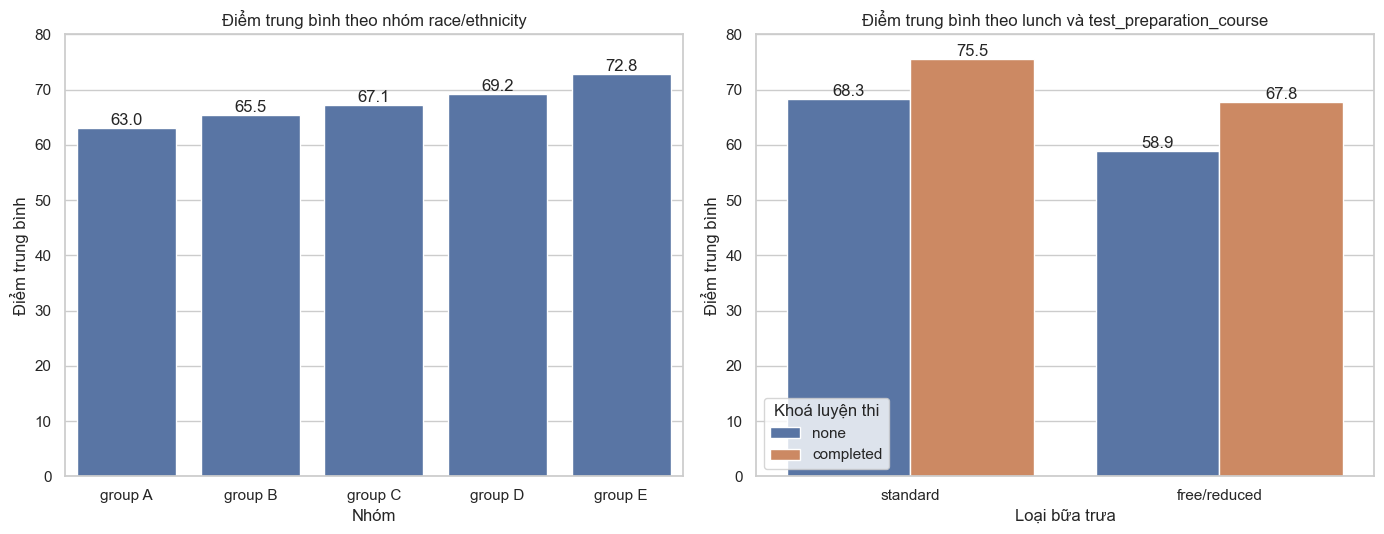

**Nhận xét:** Theo `race_ethnicity`, nhóm `group E` có điểm trung bình cao nhất (72.8) và nhóm `group A` thấp nhất (63.0), chênh 9.8 điểm. Theo `lunch`, nhóm `standard` cao hơn nhóm `free/reduced` 8.6 điểm; theo `test_preparation_course`, nhóm `completed` cao hơn nhóm `none` 7.6 điểm. Ở biểu đồ (b), trong cả hai loại bữa trưa, nhóm đã hoàn thành luyện thi đều có cột cao hơn, tức hai yếu tố này cùng tác động lên điểm.

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# (a) Điểm trung bình theo nhóm race_ethnicity (A đến E)
thu_tu_nhom = sorted(df[GROUP_COL].unique())
# errorbar=None bỏ thanh sai số để nhãn số không bị đè
sns.barplot(data=df, x=GROUP_COL, y=TB, order=thu_tu_nhom, color="#4C72B0", errorbar=None, ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt="%.1f")      # ghi giá trị trên đầu mỗi cột
axes[0].set_ylim(0, 80)
axes[0].set_title("Điểm trung bình theo nhóm race/ethnicity")
axes[0].set_xlabel("Nhóm")
axes[0].set_ylabel("Điểm trung bình")

# (b) Điểm trung bình theo loại bữa trưa, tách theo khoá luyện thi (hue)
sns.barplot(data=df, x="lunch", y=TB, hue="test_preparation_course", errorbar=None, ax=axes[1])
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.1f")
axes[1].set_ylim(0, 80)
axes[1].set_title("Điểm trung bình theo lunch và test_preparation_course")
axes[1].set_xlabel("Loại bữa trưa")
axes[1].set_ylabel("Điểm trung bình")
axes[1].legend(title="Khoá luyện thi")
luu_hinh("3_2_1_barplot")

tb_nhom = df.groupby(GROUP_COL)[TB].mean()
tb_lunch = df.groupby("lunch")[TB].mean()
tb_luyen = df.groupby("test_preparation_course")[TB].mean()
# Kiểm tra: trong từng loại bữa trưa, nhóm có luyện thi (completed) có điểm cao hơn nhóm none không
tb_2_chieu = df.pivot_table(index="lunch", columns="test_preparation_course", values=TB, aggfunc="mean")
luyen_thi_cao_hon = bool((tb_2_chieu["completed"] > tb_2_chieu["none"]).all())
display(Markdown(
    f"**Nhận xét:** Theo `race_ethnicity`, nhóm `{tb_nhom.idxmax()}` có điểm trung bình cao nhất ({tb_nhom.max():.1f}) và nhóm `{tb_nhom.idxmin()}` thấp nhất ({tb_nhom.min():.1f}), "
    f"chênh {tb_nhom.max() - tb_nhom.min():.1f} điểm. "
    f"Theo `lunch`, nhóm `{tb_lunch.idxmax()}` cao hơn nhóm `{tb_lunch.idxmin()}` {tb_lunch.max() - tb_lunch.min():.1f} điểm; "
    f"theo `test_preparation_course`, nhóm `{tb_luyen.idxmax()}` cao hơn nhóm `{tb_luyen.idxmin()}` {tb_luyen.max() - tb_luyen.min():.1f} điểm. "
    + ("Ở biểu đồ (b), trong cả hai loại bữa trưa, nhóm đã hoàn thành luyện thi đều có cột cao hơn, tức hai yếu tố này cùng tác động lên điểm."
       if luyen_thi_cao_hon else "Ở biểu đồ (b), tác động của khoá luyện thi không đồng nhất giữa hai loại bữa trưa.")
))

### 3.2.2 Pie Chart (tỷ lệ phần trăm của `xep_loai` và `ket_qua`)

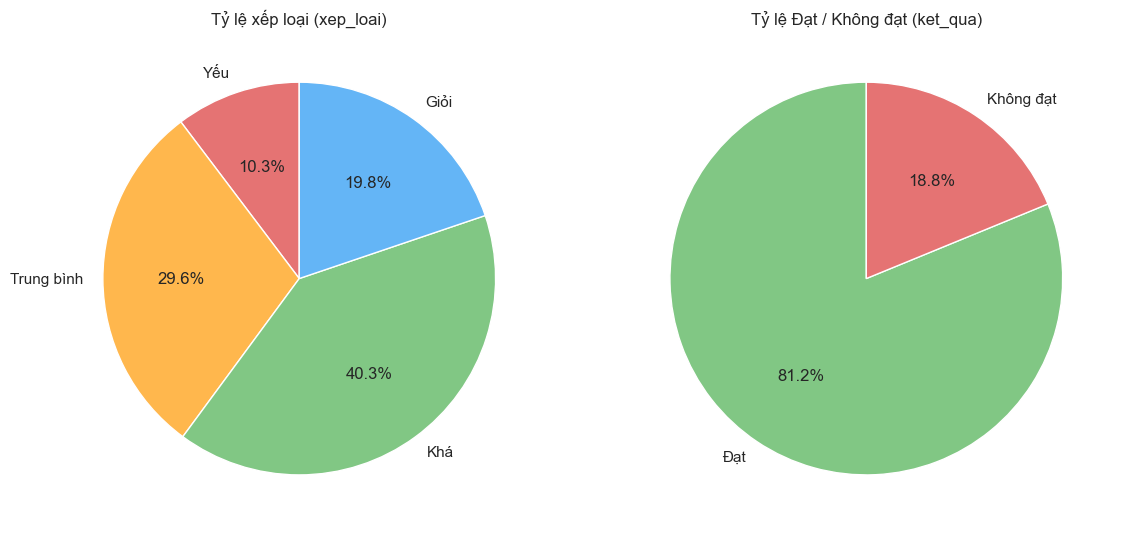

**Nhận xét:** Nhóm xếp loại chiếm tỷ lệ lớn nhất là `Khá` (40.3%), nhóm nhỏ nhất là `Yếu` (10.3%). Tỷ lệ Yếu / Trung bình / Khá / Giỏi lần lượt là 10.3% / 29.6% / 40.3% / 19.8%. Về kết quả, có 81.2% học sinh Đạt (cả 3 môn từ 50 điểm trở lên) và 18.8% Không đạt.

In [17]:

# value_counts() đếm số học sinh của từng nhóm; reindex() sắp theo thứ tự Yếu, Trung bình, Khá, Giỏi
dem_xep_loai = df["xep_loai"].value_counts().reindex(THU_TU_XEP_LOAI)
dem_ket_qua = df["ket_qua"].value_counts().reindex(["Đạt", "Không đạt"])     # cố định thứ tự để màu xanh = Đạt, đỏ = Không đạt

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
# plot.pie của Pandas; autopct ghi phần trăm lên từng miếng; startangle=90 bắt đầu từ đỉnh
dem_xep_loai.plot.pie(ax=axes[0], autopct="%1.1f%%", startangle=90, ylabel="",
                      colors=["#E57373", "#FFB74D", "#81C784", "#64B5F6"], wedgeprops={"edgecolor": "white"})
axes[0].set_title("Tỷ lệ xếp loại (xep_loai)")
dem_ket_qua.plot.pie(ax=axes[1], autopct="%1.1f%%", startangle=90, ylabel="",
                     colors=["#81C784", "#E57373"], wedgeprops={"edgecolor": "white"})
axes[1].set_title("Tỷ lệ Đạt / Không đạt (ket_qua)")
luu_hinh("3_2_2_piechart")

ty_le = (dem_xep_loai / dem_xep_loai.sum() * 100).round(1)
ty_le_kq = (dem_ket_qua / dem_ket_qua.sum() * 100).round(1)
display(Markdown(
    f"**Nhận xét:** Nhóm xếp loại chiếm tỷ lệ lớn nhất là `{ty_le.idxmax()}` ({ty_le.max()}%), nhóm nhỏ nhất là `{ty_le.idxmin()}` ({ty_le.min()}%). "
    f"Tỷ lệ Yếu / Trung bình / Khá / Giỏi lần lượt là {ty_le['Yếu']}% / {ty_le['Trung bình']}% / {ty_le['Khá']}% / {ty_le['Giỏi']}%. "
    f"Về kết quả, có {ty_le_kq.get('Đạt', 0)}% học sinh Đạt (cả 3 môn từ 50 điểm trở lên) và {ty_le_kq.get('Không đạt', 0)}% Không đạt."
))

## 3.3 Mối quan hệ và Xu hướng (Relationship and Trend)

#### Scatter Plot kèm đường hồi quy (regression line) bằng Seaborn.

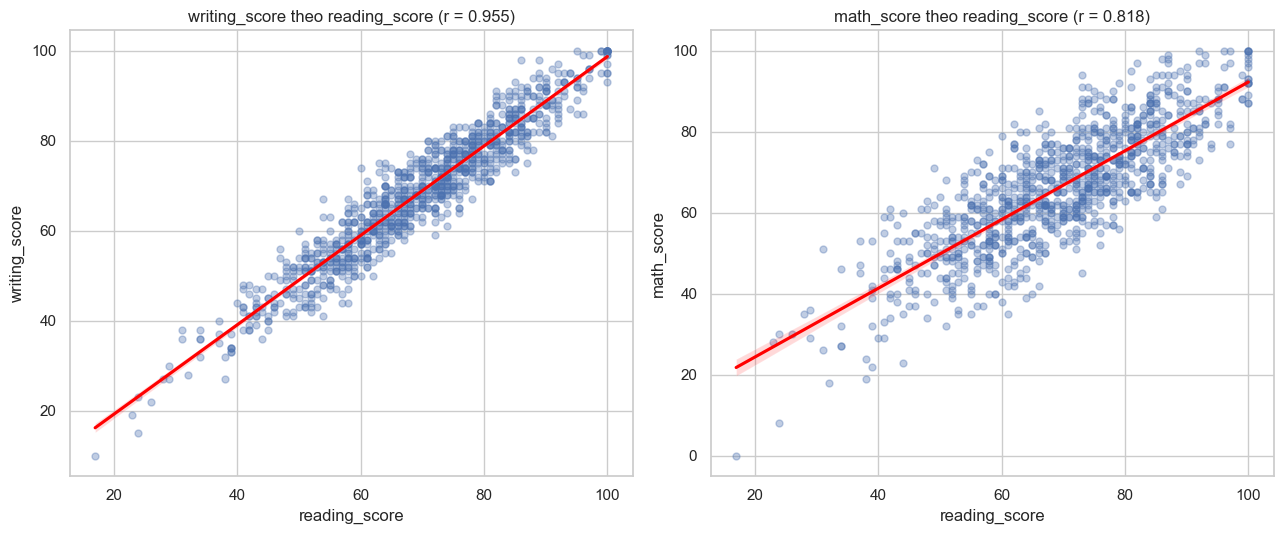

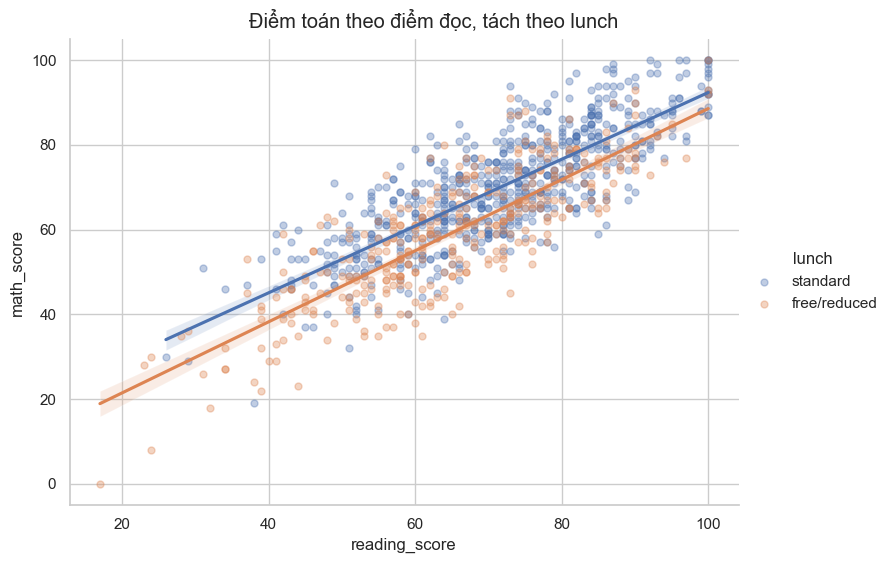

**Nhận xét:** Reading và writing có tương quan dương (r = 0.955); mỗi +1 điểm reading ứng với khoảng +0.99 điểm writing. Reading và math có r = 0.818 (hệ số góc khoảng 0.85), thấp hơn cặp reading - writing nên điểm đọc dự đoán điểm toán kém chính xác hơn dự đoán điểm viết. Khi tách theo `lunch`, ở cùng mức điểm đọc 70 thì điểm toán dự đoán là free/reduced: 63.4; standard: 68.7 (chênh 5.3 điểm), tức đây là khoảng cách giữa hai đường hồi quy ở cùng điểm đọc.

In [18]:
# Hai cặp biến: (đọc, viết) và (đọc, toán)
cap_bien = [("reading_score", "writing_score"), ("reading_score", "math_score")]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (x, y) in zip(axes, cap_bien):
    # regplot vẽ scatter và đường hồi quy tuyến tính; alpha làm điểm mờ để thấy chỗ chồng nhau
    sns.regplot(data=df, x=x, y=y, scatter_kws={"alpha": 0.35, "s": 25}, line_kws={"color": "red"}, ax=ax)
    r = df[x].corr(df[y])      # hệ số tương quan Pearson
    ax.set_title(f"{y} theo {x} (r = {r:.3f})")
luu_hinh("3_3_scatter_regplot")

# Hệ số góc của đường hồi quy: mỗi +1 điểm đọc thì điểm viết / toán tăng thêm bao nhiêu
he_so = {y: np.polyfit(df[x], df[y], 1)[0] for x, y in cap_bien}

# Tách đường hồi quy theo từng loại bữa trưa (hue) để xem xu hướng có khác nhau giữa hai nhóm không
g = sns.lmplot(data=df, x="reading_score", y="math_score", hue="lunch", height=5.5, aspect=1.4,
               scatter_kws={"alpha": 0.35, "s": 25})
g.figure.suptitle("Điểm toán theo điểm đọc, tách theo lunch", y=1.02)
g.savefig(os.path.join(CHART_FOLDER, "3_3_lmplot_lunch.png"), dpi=150, bbox_inches="tight")
plt.show()

# Điểm toán dự đoán ở cùng mức điểm đọc = 70 của từng nhóm lunch
du_doan = {nhom: np.polyval(np.polyfit(d["reading_score"], d["math_score"], 1), 70) for nhom, d in df.groupby("lunch")}
r_doc_viet = df["reading_score"].corr(df["writing_score"])
r_doc_toan = df["reading_score"].corr(df["math_score"]) 
display(Markdown(
    f"**Nhận xét:** Reading và writing có tương quan dương (r = {r_doc_viet:.3f}); "
    f"mỗi +1 điểm reading ứng với khoảng +{he_so['writing_score']:.2f} điểm writing. "
    f"Reading và math có r = {r_doc_toan:.3f} (hệ số góc khoảng {he_so['math_score']:.2f}), "
    + ("thấp hơn cặp reading - writing nên điểm đọc dự đoán điểm toán kém chính xác hơn dự đoán điểm viết. " if r_doc_toan < r_doc_viet
       else "không thấp hơn cặp reading - writing. ") +
    f"Khi tách theo `lunch`, ở cùng mức điểm đọc 70 thì điểm toán dự đoán là "
    + "; ".join(f"{nhom}: {v:.1f}" for nhom, v in du_doan.items())
    + f" (chênh {max(du_doan.values()) - min(du_doan.values()):.1f} điểm), tức đây là khoảng cách giữa hai đường hồi quy ở cùng điểm đọc."
))

## 3.4 Trực quan hoá cơ bản (Matplotlib Core)

#### Chỉ dùng Matplotlib và cấu trúc Python cơ bản (list, dictionary), không dùng Pandas/Seaborn để vẽ.

Chọn 5 học sinh đầu tiên, vẽ biểu đồ thanh cho điểm trung bình và biểu đồ đường cho điểm từng môn.

Điểm trung bình: [72.67, 82.33, 92.67, 49.33, 76.33]
Điểm từng môn: {'Toán': [72, 69, 90, 47, 76], 'Đọc': [72, 90, 95, 57, 78], 'Viết': [74, 88, 93, 44, 75]}


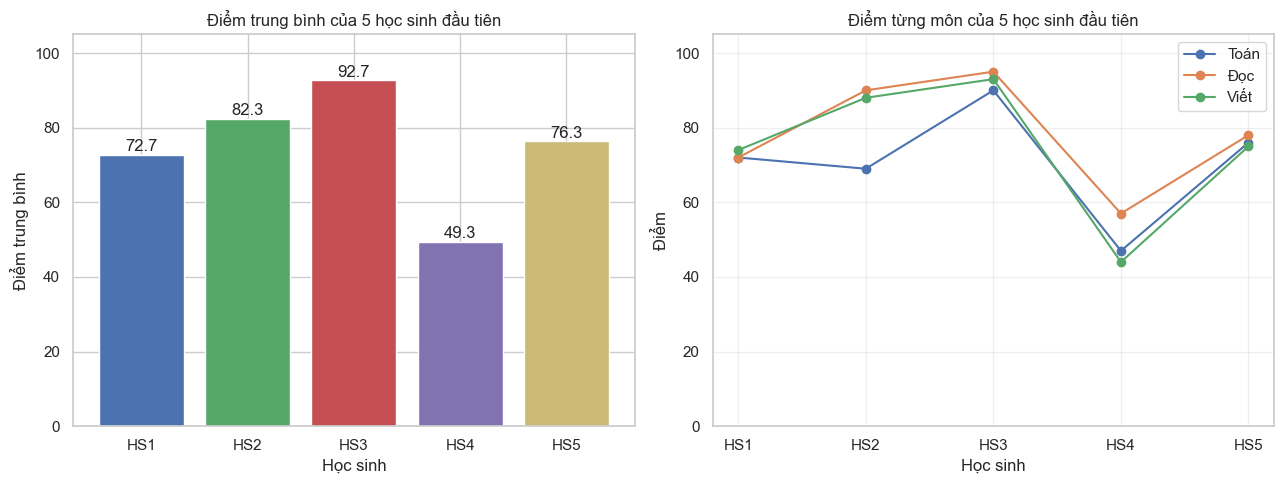

**Nhận xét:** Trong 5 học sinh đầu tiên, `HS3` có điểm trung bình cao nhất (92.7) và `HS4` thấp nhất (49.3). Ba đường điểm của các môn có hình dạng khá giống nhau giữa các học sinh, phù hợp với tương quan dương mạnh giữa ba môn ở Phần II.

In [19]:
# Lấy dữ liệu của 5 học sinh đầu tiên ra list và dictionary thuần của Python (chỉ bước này đụng đến DataFrame)
ten_hs = ["HS1", "HS2", "HS3", "HS4", "HS5"]
diem_tb = df[TB].head(5).tolist()                                  # list điểm trung bình
diem_mon = {"Toán": df["math_score"].head(5).tolist(),             # dictionary: tên môn -> list điểm
            "Đọc": df["reading_score"].head(5).tolist(),
            "Viết": df["writing_score"].head(5).tolist()}
print("Điểm trung bình:", diem_tb)
print("Điểm từng môn:", diem_mon)

# Từ đây chỉ dùng matplotlib và Python cơ bản
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# (a) Biểu đồ thanh: điểm trung bình của 5 học sinh
mau_cot = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]
axes[0].bar(ten_hs, diem_tb, color=mau_cot)
for ten, gia_tri in zip(ten_hs, diem_tb):               # ghi giá trị lên đầu mỗi cột bằng vòng lặp
    axes[0].text(ten, gia_tri + 1, f"{gia_tri:.1f}", ha="center")
axes[0].set_ylim(0, 105)
axes[0].set_title("Điểm trung bình của 5 học sinh đầu tiên")
axes[0].set_xlabel("Học sinh")
axes[0].set_ylabel("Điểm trung bình")

# (b) Biểu đồ đường: mỗi môn là một đường (duyệt dictionary bằng .items())
for mon, ds in diem_mon.items():
    axes[1].plot(ten_hs, ds, marker="o", label=mon)
axes[1].set_ylim(0, 105)
axes[1].set_title("Điểm từng môn của 5 học sinh đầu tiên")
axes[1].set_xlabel("Học sinh")
axes[1].set_ylabel("Điểm")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
luu_hinh("3_4_matplotlib_core")

# Nhận xét bằng Python cơ bản: max, min, index trên list
hs_cao = ten_hs[diem_tb.index(max(diem_tb))]
hs_thap = ten_hs[diem_tb.index(min(diem_tb))]
display(Markdown(
    f"**Nhận xét:** Trong 5 học sinh đầu tiên, `{hs_cao}` có điểm trung bình cao nhất ({max(diem_tb):.1f}) và `{hs_thap}` thấp nhất ({min(diem_tb):.1f}). "
    f"Ba đường điểm của các môn có hình dạng khá giống nhau giữa các học sinh, phù hợp với tương quan dương mạnh giữa ba môn ở Phần II."
))

# PHẦN IV: TỔNG HỢP VÀ BÁO CÁO

## 4.1 Báo cáo toàn diện: hàm `comprehensive_report()`

#### Hiển thị tổng số record, phân bố (số lượng và tỷ lệ phần trăm), thống kê điểm và các điểm nổi bật.

In [20]:
def comprehensive_report(data, score_cols=None, cat_cols=None):
    """In báo cáo tổng hợp: tổng số record, phân bố (số lượng và %) của các cột phân loại,
    thống kê của các cột điểm và các điểm nổi bật."""
    # Giá trị mặc định cho các tham số
    if score_cols is None:
        score_cols = DIEM + [TB]
    if cat_cols is None:
        cat_cols = CAC_YEU_TO + ["xep_loai", "ket_qua"]
    tong = len(data)

    # ---------- 1. Tổng quan ----------
    print("=" * 70)
    print("BÁO CÁO TỔNG HỢP")
    print("=" * 70)
    print("1. TỔNG QUAN")
    print("   Tổng số record     :", tong)
    print("   Số cột             :", data.shape[1])
    print("   Giá trị thiếu      :", int(data.isnull().sum().sum()))
    print("   Dòng trùng         :", int(data.duplicated().sum()))

    # ---------- 2. Phân bố các cột phân loại (số lượng và %) ----------
    print("\n2. PHÂN BỐ CÁC CỘT PHÂN LOẠI (số lượng và tỷ lệ %)")
    for cot in cat_cols:
        dem = data[cot].value_counts()
        if cot in THU_TU:                                # cột có thứ bậc thì sắp đúng thứ tự
            dem = dem.reindex(THU_TU[cot])
        bang = pd.DataFrame({"số lượng": dem, "tỷ lệ (%)": (dem / tong * 100).round(1)})
        print(f"\n   --- {cot} ---")
        print(bang.to_string())

    # ---------- 3. Thống kê các cột điểm ----------
    print("\n3. THỐNG KÊ CÁC CỘT ĐIỂM")
    print(data[score_cols].agg(["mean", "median", "std", "min", "max"]).round(2).T.to_string())

    # ---------- 4. Điểm nổi bật ----------
    tb_mon = data[DIEM].mean()
    print("\n4. ĐIỂM NỔI BẬT")
    print(f"   Môn có điểm TB cao nhất : {tb_mon.idxmax()} ({tb_mon.max():.2f})")
    print(f"   Môn có điểm TB thấp nhất: {tb_mon.idxmin()} ({tb_mon.min():.2f})")
    print(f"   Điểm trung bình cao nhất / thấp nhất của một học sinh: {data[TB].max():.2f} / {data[TB].min():.2f}")
    so_hoc_sinh_100 = int((data[DIEM] == 100).any(axis=1).sum())
    print(f"   Số học sinh có ít nhất một môn đạt 100 điểm: {so_hoc_sinh_100}")
    print("=" * 70)

# Gọi hàm với dữ liệu sau Phần II
comprehensive_report(df)

BÁO CÁO TỔNG HỢP
1. TỔNG QUAN
   Tổng số record     : 1000
   Số cột             : 18
   Giá trị thiếu      : 0
   Dòng trùng         : 0

2. PHÂN BỐ CÁC CỘT PHÂN LOẠI (số lượng và tỷ lệ %)

   --- gender ---
        số lượng  tỷ lệ (%)
gender                     
female       518       51.8
male         482       48.2

   --- race_ethnicity ---
                số lượng  tỷ lệ (%)
race_ethnicity                     
group C              319       31.9
group D              262       26.2
group B              190       19.0
group E              140       14.0
group A               89        8.9

   --- parental_level_of_education ---
                             số lượng  tỷ lệ (%)
parental_level_of_education                     
some high school                  179       17.9
high school                       196       19.6
some college                      226       22.6
associate's degree                222       22.2
bachelor's degree                 118       11.8
master's degree  

## 4.2 Phân tích chuyên sâu: 10 học sinh cao nhất và thấp nhất

#### Xếp hạng theo cột `diem_trung_binh`, hiển thị đầy đủ tất cả các cột.

In [21]:
# Hiển thị đầy đủ mọi cột (không bị rút gọn bằng dấu ...)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)

COT_XEP_HANG = TB     # cột dùng để xếp hạng
# kind="mergesort" là sắp xếp ổn định: các học sinh bằng điểm giữ nguyên thứ tự ban đầu, nên kết quả không đổi giữa các lần chạy
top10 = df.sort_values(COT_XEP_HANG, ascending=False, kind="mergesort").head(10)
bottom10 = df.sort_values(COT_XEP_HANG, ascending=True, kind="mergesort").head(10)

print("===== 10 HỌC SINH CÓ", COT_XEP_HANG, "CAO NHẤT =====")
display(top10)
print("\n===== 10 HỌC SINH CÓ", COT_XEP_HANG, "THẤP NHẤT =====")
display(bottom10)

===== 10 HỌC SINH CÓ diem_trung_binh CAO NHẤT =====


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,tong_diem,diem_trung_binh,xep_loai,ket_qua,chuan_bi_num,lunch_num,nam_num,math_minmax,math_zscore,math_minmax_chung
458,female,group E,bachelor's degree,standard,none,100,100,100,300,100.00,Giỏi,Đạt,0,1,0,1.000000,1.685215,1.00
916,male,group E,bachelor's degree,standard,completed,100,100,100,300,100.00,Giỏi,Đạt,1,1,1,1.000000,1.685215,1.00
962,female,group E,associate's degree,standard,none,100,100,100,300,100.00,Giỏi,Đạt,0,1,0,1.000000,1.685215,1.00
114,female,group E,bachelor's degree,standard,completed,99,100,100,299,99.67,Giỏi,Đạt,1,1,0,0.985714,1.620841,0.99
179,female,group D,some high school,standard,completed,97,100,100,297,99.00,Giỏi,Đạt,1,1,0,0.959459,2.152413,0.97
712,female,group D,some college,standard,none,98,100,99,297,99.00,Giỏi,Đạt,0,1,0,0.972973,2.225038,0.98
165,female,group C,bachelor's degree,standard,completed,96,100,100,296,98.67,Giỏi,Đạt,1,1,0,0.979592,2.123259,0.96
625,male,group D,some college,standard,completed,100,97,99,296,98.67,Giỏi,Đạt,1,1,1,1.000000,2.370288,1.00
149,male,group E,associate's degree,free/reduced,completed,100,100,93,293,97.67,Giỏi,Đạt,1,0,1,1.000000,1.685215,1.00
685,female,group E,master's degree,standard,completed,94,99,100,293,97.67,Giỏi,Đạt,1,1,0,0.914286,1.298972,0.94



===== 10 HỌC SINH CÓ diem_trung_binh THẤP NHẤT =====


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,tong_diem,diem_trung_binh,xep_loai,ket_qua,chuan_bi_num,lunch_num,nam_num,math_minmax,math_zscore,math_minmax_chung
59,female,group C,some high school,free/reduced,none,0,17,10,27,9.00,Yếu,Không đạt,0,0,0,0.000000,-4.340228,0.00
980,female,group B,high school,free/reduced,none,8,24,23,55,18.33,Yếu,Không đạt,0,0,0,0.000000,-3.584946,0.08
596,male,group B,high school,free/reduced,none,30,24,15,69,23.00,Yếu,Không đạt,0,0,1,0.247191,-2.162672,0.30
327,male,group A,some college,free/reduced,none,28,23,19,70,23.33,Yếu,Không đạt,0,0,1,0.000000,-2.315582,0.28
17,female,group B,some high school,free/reduced,none,18,32,28,78,26.00,Yếu,Không đạt,0,0,0,0.112360,-2.938458,0.18
76,male,group E,some high school,standard,none,30,26,22,78,26.00,Yếu,Không đạt,0,1,1,0.000000,-2.820954,0.30
601,female,group C,high school,standard,none,29,29,30,88,29.33,Yếu,Không đạt,0,1,0,0.295918,-2.387716,0.29
338,female,group B,some high school,free/reduced,none,24,38,27,89,29.67,Yếu,Không đạt,0,0,0,0.179775,-2.550565,0.24
787,female,group B,some college,standard,none,19,38,32,89,29.67,Yếu,Không đạt,0,1,0,0.123596,-2.873809,0.19
211,male,group C,some college,free/reduced,none,35,28,27,90,30.00,Yếu,Không đạt,0,0,1,0.357143,-1.983748,0.35


In [22]:
# So sánh đặc điểm của hai nhóm: đếm số học sinh theo từng giá trị của các cột phân loại
for cot in ["lunch", "test_preparation_course", "gender"]:
    bang = pd.concat([top10[cot].value_counts(), bottom10[cot].value_counts()], axis=1, keys=["Top 10", "Bottom 10"])
    print(f"\n--- {cot} ---")
    print(bang.fillna(0).astype(int).to_string())

top_std = int((top10["lunch"] == "standard").sum())
bot_std = int((bottom10["lunch"] == "standard").sum())
top_lt = int((top10["test_preparation_course"] == "completed").sum())
bot_lt = int((bottom10["test_preparation_course"] == "completed").sum())
display(Markdown(
    f"**Nhận xét:** Nhóm 10 học sinh cao nhất có điểm trung bình từ {top10[COT_XEP_HANG].min():.2f} đến {top10[COT_XEP_HANG].max():.2f}, "
    f"nhóm thấp nhất từ {bottom10[COT_XEP_HANG].min():.2f} đến {bottom10[COT_XEP_HANG].max():.2f}. "
    f"Trong top 10 có {top_std}/10 học sinh ăn trưa `standard` và {top_lt}/10 đã hoàn thành khoá luyện thi; "
    f"trong bottom 10 các con số này là {bot_std}/10 và {bot_lt}/10. "
    f"Lưu ý đây chỉ là 20 học sinh nên chỉ mang tính minh hoạ, kết luận chính dựa trên toàn bộ dữ liệu ở mục 4.3."
))


--- lunch ---
              Top 10  Bottom 10
lunch                          
standard           9          3
free/reduced       1          7

--- test_preparation_course ---
                         Top 10  Bottom 10
test_preparation_course                   
completed                     7          0
none                          3         10

--- gender ---
        Top 10  Bottom 10
gender                   
female       7          6
male         3          4


**Nhận xét:** Nhóm 10 học sinh cao nhất có điểm trung bình từ 97.67 đến 100.00, nhóm thấp nhất từ 9.00 đến 30.00. Trong top 10 có 9/10 học sinh ăn trưa `standard` và 7/10 đã hoàn thành khoá luyện thi; trong bottom 10 các con số này là 3/10 và 0/10. Lưu ý đây chỉ là 20 học sinh nên chỉ mang tính minh hoạ, kết luận chính dựa trên toàn bộ dữ liệu ở mục 4.3.

## 4.3 Yếu tố nào ảnh hưởng lớn nhất đến điểm số?

#### Biến phụ thuộc: `diem_trung_binh` (và từng môn). Biến độc lập: `gender`, `race_ethnicity`, `parental_level_of_education`, `lunch`, `test_preparation_course`.

Dùng ba thước đo bổ sung cho nhau:

- **Eta bình phương (η²):** tỷ lệ phương sai của điểm được giải thích riêng bởi một yếu tố, tính bằng `groupby` và `transform` (từ 0% đến 100%).
- **ΔR²:** mức R² của mô hình hồi quy tuyến tính (đủ 5 yếu tố) **giảm đi** khi bỏ riêng yếu tố đó, tức phần đóng góp riêng của yếu tố khi đã tính đến 4 yếu tố còn lại.
- **Chênh lệch nhóm:** hiệu giữa điểm trung bình của nhóm cao nhất và nhóm thấp nhất của yếu tố.

In [23]:
def eta_squared(data, cot_nhom, cot_diem):
    """Tỷ lệ phương sai của cot_diem được giải thích bởi cot_nhom (từ 0 đến 1)."""
    tb_chung = data[cot_diem].mean()
    ss_tong = ((data[cot_diem] - tb_chung) ** 2).sum()                          # tổng bình phương độ lệch toàn bộ
    tb_nhom = data.groupby(cot_nhom)[cot_diem].transform("mean")                 # trung bình của nhóm mà mỗi học sinh thuộc về
    ss_giua = ((tb_nhom - tb_chung) ** 2).sum()                                  # phần độ lệch do khác biệt giữa các nhóm
    return ss_giua / ss_tong

def r_binh_phuong(data, cac_yeu_to, cot_diem):
    """R^2 của hồi quy tuyến tính cot_diem theo các yếu tố (mã hoá one-hot), giải bằng bình phương tối thiểu."""
    X = pd.get_dummies(data[cac_yeu_to], drop_first=True).astype(float)         # biến chữ thành các cột 0/1
    X.insert(0, "hang_so", 1.0)                                                 # cột hằng số (intercept)
    y = data[cot_diem].to_numpy(dtype=float)
    beta = np.linalg.lstsq(X.to_numpy(), y, rcond=None)[0]                      # hệ số hồi quy
    phan_du = y - X.to_numpy() @ beta
    return 1 - (phan_du ** 2).sum() / ((y - y.mean()) ** 2).sum()

# ---------- Thước đo 1: eta^2 (%) cho điểm trung bình và từng môn ----------
bang_eta = pd.DataFrame({cot_diem: {yt: eta_squared(df, yt, cot_diem) * 100 for yt in CAC_YEU_TO}
                         for cot_diem in DIEM + [TB]})
bang_eta = bang_eta.sort_values(TB, ascending=False).round(2)
print("η² (%) = phần trăm phương sai điểm được giải thích bởi từng yếu tố")
print(bang_eta)

# ---------- Thước đo 2: Delta R^2 khi bỏ từng yếu tố khỏi mô hình ----------
r2_day_du = r_binh_phuong(df, CAC_YEU_TO, TB)
delta_r2 = {yt: (r2_day_du - r_binh_phuong(df, [k for k in CAC_YEU_TO if k != yt], TB)) * 100 for yt in CAC_YEU_TO}

# ---------- Thước đo 3: chênh lệch điểm trung bình giữa nhóm cao nhất và thấp nhất ----------
chenh_lech = {}
for yt in CAC_YEU_TO:
    tb_nhom = df.groupby(yt)[TB].mean()
    chenh_lech[yt] = tb_nhom.max() - tb_nhom.min()

# Gộp 3 thước đo vào một bảng, xếp theo η²
bang_tong_hop = pd.DataFrame({"eta2_pct": bang_eta[TB],
                              "delta_r2_pct": pd.Series(delta_r2),
                              "chenh_lech_nhom": pd.Series(chenh_lech)}).sort_values("eta2_pct", ascending=False).round(2)
print("\nR² của mô hình đủ 5 yếu tố:", round(r2_day_du * 100, 2), "%")
print(bang_tong_hop)

η² (%) = phần trăm phương sai điểm được giải thích bởi từng yếu tố
                             math_score  reading_score  writing_score  diem_trung_binh
lunch                             12.31           5.27           6.04             8.41
test_preparation_course            3.16           5.85           9.79             6.59
parental_level_of_education        3.18           4.46           6.77             5.13
race_ethnicity                     5.54           2.21           2.80             3.53
gender                             2.82           5.97           9.07             1.71

R² của mô hình đủ 5 yếu tố: 24.23 %
                             eta2_pct  delta_r2_pct  chenh_lech_nhom
lunch                            8.41          8.63             8.64
test_preparation_course          6.59          6.50             7.63
parental_level_of_education      5.13          4.19            10.50
race_ethnicity                   3.53          2.20             9.76
gender                       

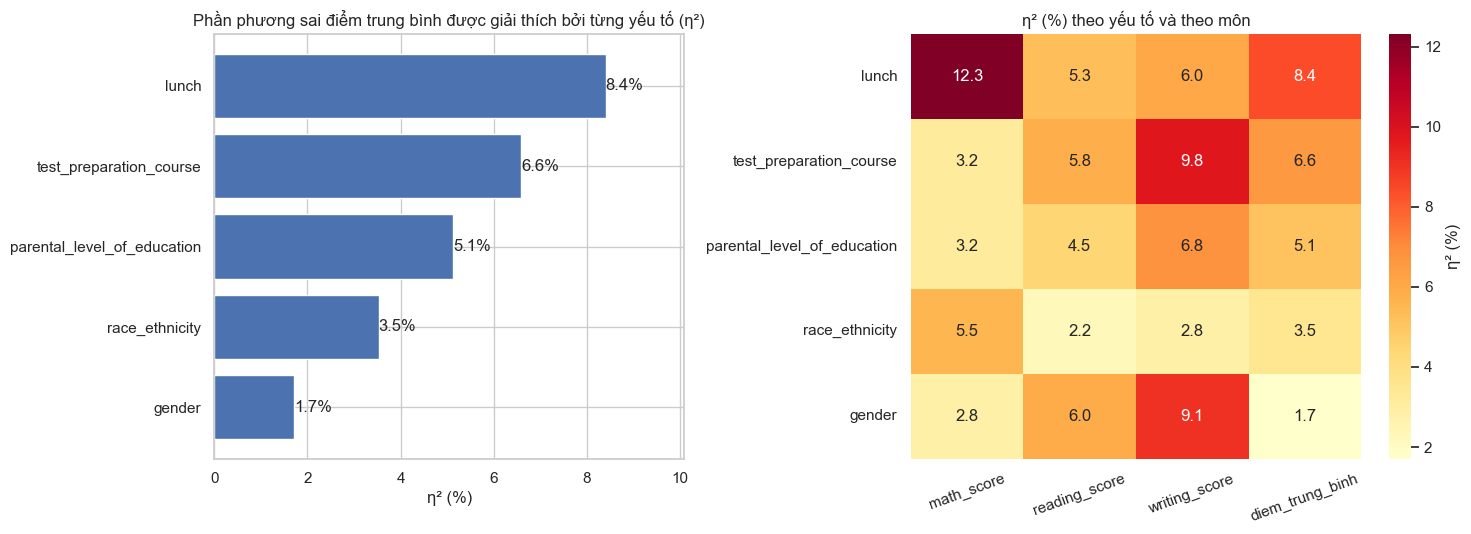

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.2]})

# (a) Biểu đồ thanh ngang: η² của từng yếu tố đối với điểm trung bình (yếu tố mạnh nhất nằm trên cùng)
sap_xep = bang_tong_hop["eta2_pct"].sort_values()
axes[0].barh(sap_xep.index, sap_xep.values, color="#4C72B0")
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%")
axes[0].set_title("Phần phương sai điểm trung bình được giải thích bởi từng yếu tố (η²)")
axes[0].set_xlabel("η² (%)")
axes[0].set_xlim(0, sap_xep.max() * 1.2)     # chừa chỗ bên phải cho nhãn %

# (b) Heatmap: η² của từng yếu tố đối với từng môn, để thấy yếu tố nào tác động môn nào
sns.heatmap(bang_eta, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "η² (%)"}, ax=axes[1])
axes[1].set_title("η² (%) theo yếu tố và theo môn")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=20)     # xoay nhãn trục x để không dính nhau
luu_hinh("4_3_anh_huong")

In [25]:
# ---------- Điểm trung bình theo từng nhóm của yếu tố mạnh nhất, để thấy chiều của tác động ----------
yeu_to_manh = bang_tong_hop["eta2_pct"].idxmax()
print("Điểm trung bình theo", yeu_to_manh)
print(df.groupby(yeu_to_manh)[TB].agg(["count", "mean", "std"]).round(2).sort_values("mean", ascending=False))

# ---------- Kết luận (số liệu lấy trực tiếp từ kết quả tính ở trên) ----------
TEN_VN = {"gender": "giới tính (gender)", "race_ethnicity": "nhóm chủng tộc (race_ethnicity)",
          "parental_level_of_education": "trình độ học vấn của phụ huynh (parental_level_of_education)",
          "lunch": "loại bữa trưa (lunch)", "test_preparation_course": "khoá luyện thi (test_preparation_course)"}
thu_hang = bang_tong_hop["eta2_pct"]
yeu_to_delta = bang_tong_hop["delta_r2_pct"].idxmax()
tb_nhom = df.groupby(yeu_to_manh)[TB].mean().sort_values(ascending=False)
gt = bang_eta.loc["gender"]
tuong_quan_doc_viet = df["reading_score"].corr(df["writing_score"])

dong = [
    f"**Kết luận Phần IV:**",
    f"1. **Biến phụ thuộc** là điểm trung bình (`{TB}`), **biến độc lập có ảnh hưởng lớn nhất** là **{TEN_VN[yeu_to_manh]}**: "
    f"riêng yếu tố này giải thích {thu_hang.max():.1f}% phương sai điểm trung bình, theo sau là {TEN_VN[thu_hang.index[1]]} ({thu_hang.iloc[1]:.1f}%) "
    f"và {TEN_VN[thu_hang.index[2]]} ({thu_hang.iloc[2]:.1f}%); yếu tố yếu nhất là {TEN_VN[thu_hang.index[-1]]} ({thu_hang.iloc[-1]:.1f}%).",
    f"2. Khi tính đến cả 4 yếu tố còn lại (ΔR²), yếu tố đóng góp riêng nhiều nhất là {TEN_VN[yeu_to_delta]} (ΔR² = {bang_tong_hop.loc[yeu_to_delta, 'delta_r2_pct']:.1f}%)"
    + (", **trùng** với kết quả xếp hạng theo η², nên kết luận ở mục 1 khá vững." if yeu_to_delta == yeu_to_manh
       else f", **khác** với xếp hạng theo η² ({yeu_to_manh}), cho thấy một phần ảnh hưởng của yếu tố đó bị chồng lấn với các yếu tố khác."),
    f"3. Chiều tác động: trong yếu tố mạnh nhất, nhóm `{tb_nhom.index[0]}` có điểm trung bình cao nhất ({tb_nhom.iloc[0]:.1f}) và nhóm `{tb_nhom.index[-1]}` thấp nhất ({tb_nhom.iloc[-1]:.1f}), "
    f"chênh {tb_nhom.iloc[0] - tb_nhom.iloc[-1]:.1f} điểm (xem thêm biểu đồ thanh ở 3.2.1 và box plot ở 3.1.2).",
    f"4. `gender` cần xét theo từng môn: η² là {gt['math_score']:.1f}% với math, {gt['reading_score']:.1f}% với reading và {gt['writing_score']:.1f}% với writing. "
    f"Ở Phần II, nam hơn nữ ở toán nhưng kém hơn ở đọc và viết, hai chiều ngược nhau nên bị triệt tiêu một phần khi lấy điểm trung bình.",
    f"5. Cả 5 yếu tố cùng nhau giải thích khoảng {r2_day_du * 100:.1f}% phương sai điểm trung bình; phần còn lại ({100 - r2_day_du * 100:.1f}%) đến từ các yếu tố không có trong dữ liệu "
    f"(thời gian tự học, năng lực nền, chất lượng giảng dạy,...)" + (" nên chỉ dựa vào các cột này thì chưa dự đoán chính xác điểm của từng học sinh." if r2_day_du < 0.5 else "."),
    f"6. Giữa các môn, reading và writing có tương quan rất mạnh (r = {tuong_quan_doc_viet:.3f}), thể hiện ở scatter plot mục 3.3: học sinh giỏi một môn ngôn ngữ thường giỏi môn còn lại.",
    f"7. **Lưu ý:** đây là dữ liệu quan sát nên mối liên hệ không đồng nghĩa với nhân quả. Ví dụ loại bữa trưa nhiều khả năng phản ánh điều kiện kinh tế gia đình chứ không phải bản thân bữa ăn làm điểm thay đổi.",
]
display(Markdown("\n\n".join(dong)))

Điểm trung bình theo lunch
              count   mean    std
lunch                            
standard        645  70.84  13.19
free/reduced    355  62.20  14.46


**Kết luận Phần IV:**

1. **Biến phụ thuộc** là điểm trung bình (`diem_trung_binh`), **biến độc lập có ảnh hưởng lớn nhất** là **loại bữa trưa (lunch)**: riêng yếu tố này giải thích 8.4% phương sai điểm trung bình, theo sau là khoá luyện thi (test_preparation_course) (6.6%) và trình độ học vấn của phụ huynh (parental_level_of_education) (5.1%); yếu tố yếu nhất là giới tính (gender) (1.7%).

2. Khi tính đến cả 4 yếu tố còn lại (ΔR²), yếu tố đóng góp riêng nhiều nhất là loại bữa trưa (lunch) (ΔR² = 8.6%), **trùng** với kết quả xếp hạng theo η², nên kết luận ở mục 1 khá vững.

3. Chiều tác động: trong yếu tố mạnh nhất, nhóm `standard` có điểm trung bình cao nhất (70.8) và nhóm `free/reduced` thấp nhất (62.2), chênh 8.6 điểm (xem thêm biểu đồ thanh ở 3.2.1 và box plot ở 3.1.2).

4. `gender` cần xét theo từng môn: η² là 2.8% với math, 6.0% với reading và 9.1% với writing. Ở Phần II, nam hơn nữ ở toán nhưng kém hơn ở đọc và viết, hai chiều ngược nhau nên bị triệt tiêu một phần khi lấy điểm trung bình.

5. Cả 5 yếu tố cùng nhau giải thích khoảng 24.2% phương sai điểm trung bình; phần còn lại (75.8%) đến từ các yếu tố không có trong dữ liệu (thời gian tự học, năng lực nền, chất lượng giảng dạy,...) nên chỉ dựa vào các cột này thì chưa dự đoán chính xác điểm của từng học sinh.

6. Giữa các môn, reading và writing có tương quan rất mạnh (r = 0.955), thể hiện ở scatter plot mục 3.3: học sinh giỏi một môn ngôn ngữ thường giỏi môn còn lại.

7. **Lưu ý:** đây là dữ liệu quan sát nên mối liên hệ không đồng nghĩa với nhân quả. Ví dụ loại bữa trưa nhiều khả năng phản ánh điều kiện kinh tế gia đình chứ không phải bản thân bữa ăn làm điểm thay đổi.